In [5]:
n=19
g=2
mu=0
T=50
import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.optimize import root

In [6]:
def part1q1a(n, g, mu, T):
    """Part 1, question 1 (a)
    Use the variable inputs if/as needed.
    Input:
    n: number of ODEs
    g,mu: model parameters
    T: time at which perturbation energy ratio should be maximized

    Output:
    xbar: n-element array containing non-trivial equilibrium solution
    xtilde0: n-element array corresponding to computed initial condition
    eratio: computed maximum perturbation energy ratio
    """
    xbar = np.zeros(n)
    xtilde0 = np.zeros(n)
    eratio = 0.0

    def model(X, n, g, mu):
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    eventus = root(
        model,
        1 / (2 * g + 1) + 0.1 * np.random.rand(n),
        method="krylov",
        args=(n, g, mu),
    )
    x_bar = eventus.x

    B = np.zeros([n, n])
    for i in range(2, n - 1):
        B[i, i] = -1
        B[i, i - 2] = -g
        B[i, i + 1] = -g

    B[0, 0] = -1
    B[0, n - 2] = -g
    B[0, 1] = -g
    B[0, n - 3] = mu

    B[1, 1] = -1
    B[1, n - 1] = -g
    B[1, 2] = -g

    B[n - 1, n - 1] = -1
    B[n - 1, n - 3] = -g
    B[n - 1, 0] = -g

    M = np.zeros([n, n])

    for i in range(n):
        M[i, i] = 1 + np.matmul(B[i, :], x_bar)

    for i in range(n):
        for j in range(n):
            M[i, j] += B[i, j] * x_bar[i]

    matM = scipy.linalg.expm(M * T)

    U, Sigma, VT = np.linalg.svd(matM)

    eratio = Sigma[0] ** 2

    xtilde0 = VT[0, :]

    xbar = x_bar

    return xbar, xtilde0, eratio

In [7]:
def simulate1(n, X0=-1, Nt=2000, tf=1000, g=1.0, mu=0.0, flag_display=False):
    """
    Simulation code for part 1
    Input:
        n: number of ODEs
        X0: initial condition if n-element numpy array. If X0 is an integer, the code will set
        the initial condition (otherwise an array is expected).
        Nt: number of time steps
        tf: final time
        g,mu: model parameters
        flag_display: will generate a contour plot displaying results if True
    Output:
    t,x: numpy arrays containing times and simulation results
    """

    def model(t, X, n, g, mu):
        """
        Defines the system of ODEs

        Input:
        - t: time
        - X: array of variables [x_0, x_1, ..., x_{n-1}]
        - g, mu: scalar model parameters
        - n: number of ODEs (size of the system)

        Returns:
        - dXdt: array of derivatives [dx_0/dt, dx_1/dt, ..., dx_{n-1}/dt]
        """
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    # Parameters
    t_span = (0, tf)  # Time span for the integration
    if type(X0) == int:  # (modified from original version)
        X0 = 1 / (2 * g + 1) + 0.001 * np.random.rand(
            n
        )  # Random initial conditions, modify if needed

    # Solve the system
    solution = solve_ivp(
        fun=model,
        t_span=t_span,
        y0=X0,
        args=(n, g, mu),
        method="BDF",
        rtol=1e-10,
        atol=1e-10,
        t_eval=np.linspace(t_span[0], t_span[1], Nt),  # Times to evaluate the solution
    )

    t, x = (
        solution.t,
        solution.y,
    )  # (in original version of code this line was inside if-block below)
    if flag_display:
        # Plot the solution
        plt.contour(t, np.arange(n), x, 20)
        plt.xlabel("t")  # (corrected axis labels)
        plt.ylabel("i")
    return t, x

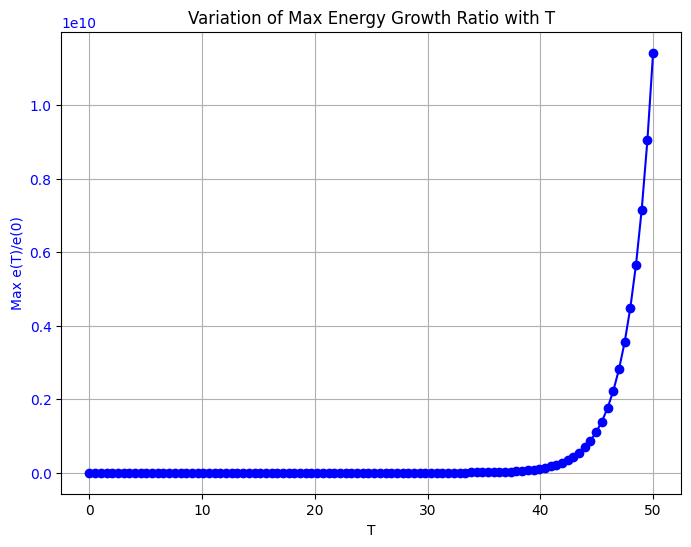

In [8]:
Ts = np.linspace(0.01, 50, 100)
rationes = []

for T in Ts:
    xbar, xtilde0, eratio_linear= part1q1a(n, g, mu, T)
    rationes.append(eratio_linear)

# Plot results
fig, ax1 = plt.subplots(figsize=(8, 6))

# Plot max energy growth ratio
ax1.plot(Ts, rationes, 'o-', label='Max e(T)/e(0)', color='blue')
ax1.set_xlabel('T')
ax1.set_ylabel('Max e(T)/e(0)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_title('Variation of Max Energy Growth Ratio with T')
ax1.grid(True)